In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
from matplotlib.image import imread

Data visualisation on all contests


To analyse contests overall, I started by analysing their popularity, using their number of captions per image and their best captions mean. I then proceeded to analyse the delta between the mean of each contest top 1 and top 2 captions. 

Popularity Analysis

The aim here is to measure raw engagement with a contest, by ranking the contest in regards to how many captions they got. More captions means more people interacted with the contest, but it does not mean the jokes were more liked.

In [1]:
#coded a function to show the desired image
images_folder = r"C:\Users\hanna\ADA\2025\newyorker_caption_contest\images"

def show_contest_image(contest_num, title_suffix=""):
    image_path = os.path.join(images_folder, f"{contest_num}.jpg")
    
    if os.path.exists(image_path):
        img = imread(image_path)
        plt.figure(figsize=(6,6))
        plt.imshow(img)
        plt.axis('off')
        plt.title(f"Contest #{contest_num} {title_suffix}")
        plt.show()
    else:
        print(f"Image for contest #{contest_num} not found.")


In [2]:
#coded a function to print the top caption by mean 
def print_top_caption(contest_num, folder_path):
    filename = f"{contest_num}.csv"
    file_path = os.path.join(folder_path, filename)
    
    df = pd.read_csv(file_path)
    top1 = df.nlargest(1, 'mean')  # top caption by mean score
    
    print(f"\nContest {contest_num} Top Caption:")
    for i, row in top1.iterrows():
        print(f"Rank 1: '{row['caption']}' with mean score {row['mean']:.3f}")

#1.1 Popularity : Analysing the nummber of Captions per contest

In [3]:
#file_path = pd.read_csv(r"C:\Users\hanna\ADA\2025\newyorker_caption_contest\data\510.csv")
folder_path = r"C:\Users\hanna\ADA\2025\newyorker_caption_contest\data"

File not found: 525.csv
File not found: 540.csv

Top 5 most popular contests:
     Contest  Num_Captions
204      716         15329
232      744         12354
228      740         11108
241      753         11069
195      707         10718

Top 5 least popular contests:
     Contest  Num_Captions
124      636          2930
86       598          2919
324      836          2032
322      834          1444
323      835          1066

Most popular contest: #716 with 15329 captions.
Least popular contest: #835 with 1066 captions.


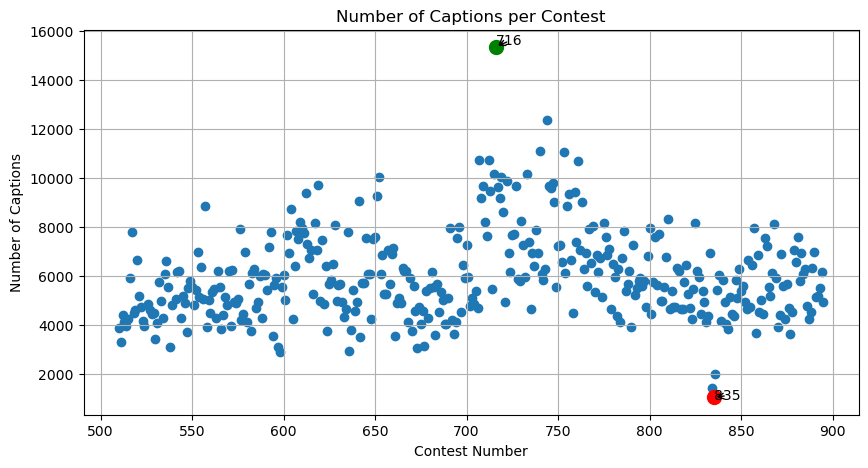

In [ ]:
contest_counts = {} #intialise caption number at 0
if not os.path.isdir(folder_path):
    raise FileNotFoundError(f"Folder not found: {folder_path}") #missing contests
for contest_num in range(510, 896):
    filename = f"{contest_num}.csv"
    file_path = os.path.join(folder_path, filename)
    if os.path.exists(file_path):
        try:
            df = pd.read_csv(file_path)
            contest_counts[contest_num] = len(df) #to get the length of the file = number of captions per contest
        except Exception as e:
            print(f"Error reading {filename}: {e}")
    else:
        print(f"File not found: {filename}")

# Turning them into Dataframes
counts_df = pd.DataFrame(list(contest_counts.items()), columns=["Contest", "Num_Captions"])
counts_df = counts_df.sort_values(by="Num_Captions", ascending=False) #ordered list of the contest with their corresponding number of captions

# printing the gist of the top and least populars
print("\nTop 5 most popular contests:")
print(counts_df.head())

print("\nTop 5 least popular contests:")
print(counts_df.tail())

# Defining the top and least popular
most_popular = counts_df.iloc[0]
least_popular = counts_df.iloc[-1]

print(f"\nMost popular contest: #{most_popular['Contest']} with {most_popular['Num_Captions']} captions.")
print(f"Least popular contest: #{least_popular['Contest']} with {least_popular['Num_Captions']} captions.")

# Visualizing
plt.figure(figsize=(10,5))
plt.scatter(counts_df["Contest"], counts_df["Num_Captions"], marker='o', linestyle='-')
# Highlight most & least popular on the scatter plot
plt.scatter(most_popular["Contest"], most_popular["Num_Captions"], color='green', s=100, label='Most popular')
plt.scatter(least_popular["Contest"], least_popular["Num_Captions"], color='red', s=100, label='Least popular')

plt.annotate(f"{int(most_popular['Contest'])}",
             xy=(most_popular['Contest'], most_popular['Num_Captions']),
             xytext=(most_popular['Contest'], most_popular['Num_Captions'] + 100),
             arrowprops=dict(facecolor='green', arrowstyle='->'),
             fontsize=10)

plt.annotate(f"{int(least_popular['Contest'])}",
             xy=(least_popular['Contest'], least_popular['Num_Captions']),
             xytext=(least_popular['Contest'], least_popular['Num_Captions'] - 100),
             arrowprops=dict(facecolor='red', arrowstyle='->'),
             fontsize=10)
plt.title("Number of Captions per Contest")
plt.xlabel("Contest Number")
plt.ylabel("Number of Captions")
plt.grid(True)
plt.show()

We are missing contest 525 and 540, but they seem to exist from online documentation

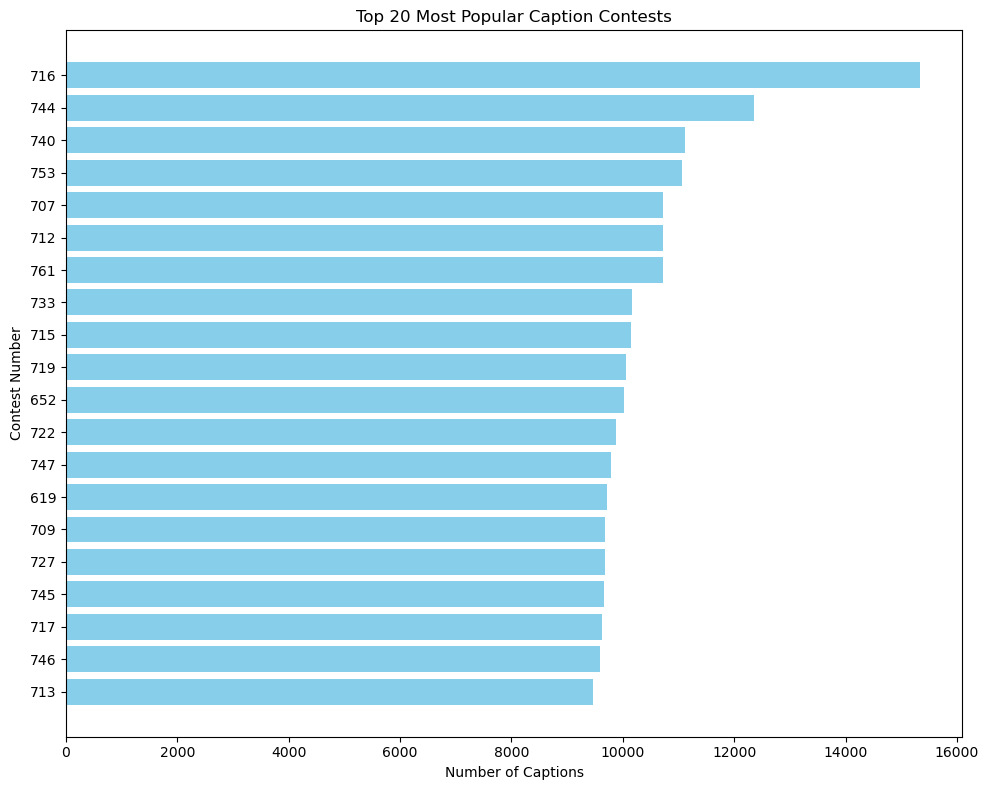

In [53]:
#20 most popular contests 
top20 = counts_df.head(20).sort_values(by="Num_Captions")

plt.figure(figsize=(10,8))
plt.barh(top20["Contest"].astype(str), top20["Num_Captions"], color='skyblue')
plt.xlabel("Number of Captions")
plt.ylabel("Contest Number")
plt.title("Top 20 Most Popular Caption Contests")
plt.tight_layout()
plt.show()

We can see that the most popular contest wins by a lot of captions. There is quite a gap between the top 1 and top 2 contest.
Contests ranging from 707-761 actually dated from April 2020 to June 2020. This corresponds to the pandemic time period, during which a big part of the Western world was in quarantine.

Contest witht the most captions : 


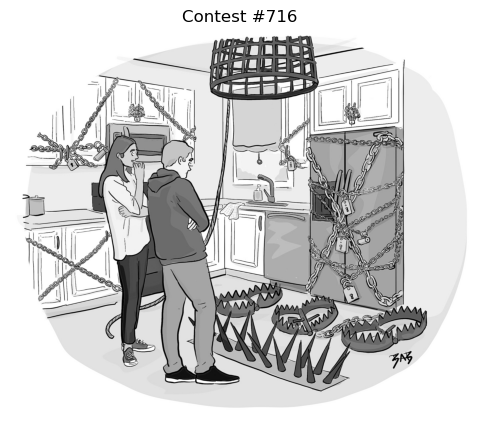

In [54]:
print("Contest witht the most captions : ")
show_contest_image(716)

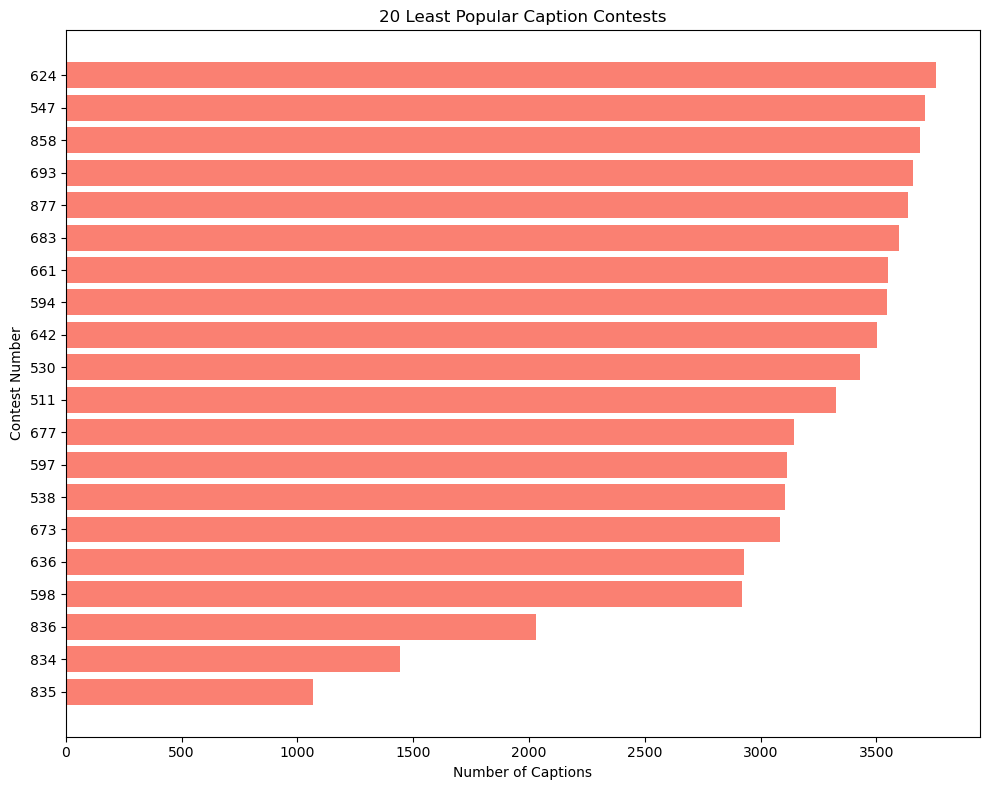

In [55]:
#top 20 least popular contest
bottom20 = counts_df.tail(20).sort_values(by="Num_Captions")
plt.figure(figsize=(10,8))
plt.barh(bottom20["Contest"].astype(str), bottom20["Num_Captions"], color='salmon')
plt.xlabel("Number of Captions")
plt.ylabel("Contest Number")
plt.title("20 Least Popular Caption Contests")
plt.tight_layout()
plt.show()

We can see a similar margin between contest 835 and 834 is quite small, rangin from less than 500 votes. Both of these are from January 2023, but I could not find a particular reason for them to have less captions.


Contest witht the least captions : 


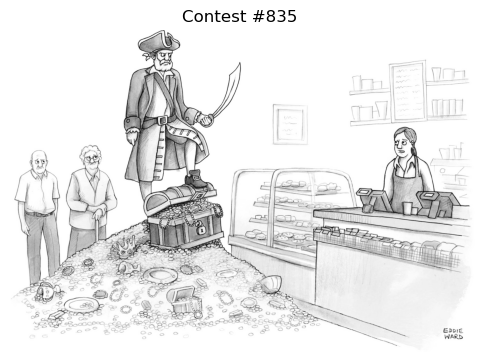

In [56]:
print("Contest witht the least captions : ")
show_contest_image(835)

1.2 Popularity Analysis : Using mean scores this time

This aims at measuring engagement in terms of how liked a caption is. Keep in mind the mean is calculated best on the different notes (+1, 0, -1) but also the numbers of total votes of the caption

File not found: 525.csv
File not found: 540.csv

Top 5 contests by mean of top 1 captions:
     Contest  Top1_Mean
88       600   2.998918
178      690   2.671296
43       555   2.634196
153      665   2.518294
7        517   2.391304

Bottom 5 contests by mean of top 1 captions:
     Contest  Top1_Mean
128      640   1.633028
383      895   1.632287
132      644   1.600000
125      637   1.576744
131      643   1.552036

Highest mean contest: #600.0 with mean score 2.999
Lowest mean contest: #643.0 with mean score 1.552


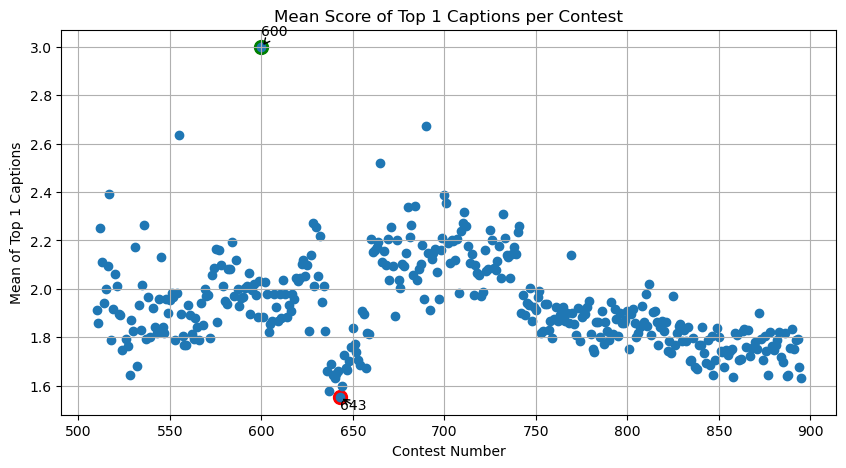

In [8]:
#now print popularity between each contest similarly to first part but using mean scores instead
top_n = 1  # number of top captions to consider
top_mean_scores = {}

for contest_num in range(510, 896):
    filename = f"{contest_num}.csv"
    file_path = os.path.join(folder_path, filename)
    
    if os.path.exists(file_path):
        try:
            df = pd.read_csv(file_path)
            if len(df) >= 1:
                top_scores = df['mean'].nlargest(top_n)
                top_mean = top_scores.mean()
                top_mean_scores[contest_num] = top_mean
            else:
                top_mean_scores[contest_num] = None
        except Exception as e:
            print(f"Error reading {filename}: {e}")
    else:
        print(f"File not found: {filename}")

# turning the results into DataFrame and sorting them
top_mean_df = pd.DataFrame(list(top_mean_scores.items()), columns=["Contest", f"Top{top_n}_Mean"])
top_mean_df = top_mean_df.dropna().sort_values(by=f"Top{top_n}_Mean", ascending=False)

# Print top and least liked contests
print(f"\nTop 5 contests by mean of top {top_n} captions:")
print(top_mean_df.head())

print(f"\nBottom 5 contests by mean of top {top_n} captions:")
print(top_mean_df.tail())

# Get highest and lowest mean contests
highest_mean = top_mean_df.iloc[0]
lowest_mean = top_mean_df.iloc[-1]

print(f"\nHighest mean contest: #{highest_mean['Contest']} with mean score {highest_mean[f'Top{top_n}_Mean']:.3f}")
print(f"Lowest mean contest: #{lowest_mean['Contest']} with mean score {lowest_mean[f'Top{top_n}_Mean']:.3f}")

# visualization
plt.figure(figsize=(10,5))
#Highlighting the highest and lowest mean contest
plt.scatter(highest_mean["Contest"], highest_mean[f"Top{top_n}_Mean"], color='green', s=100, label='Highest mean')
plt.scatter(lowest_mean["Contest"], lowest_mean[f"Top{top_n}_Mean"], color='red', s=100, label='Lowest mean')
plt.scatter(top_mean_df["Contest"], top_mean_df[f"Top{top_n}_Mean"], marker='o', linestyle='-')
plt.annotate(f"{int(highest_mean['Contest'])}",
             xy=(highest_mean['Contest'], highest_mean[f"Top{top_n}_Mean"]),
             xytext=(highest_mean['Contest'], highest_mean[f"Top{top_n}_Mean"] + 0.05),
             arrowprops=dict(facecolor='green', arrowstyle='->'),
             fontsize=10)

plt.annotate(f"{int(lowest_mean['Contest'])}",
             xy=(lowest_mean['Contest'], lowest_mean[f"Top{top_n}_Mean"]),
             xytext=(lowest_mean['Contest'], lowest_mean[f"Top{top_n}_Mean"] - 0.05),
             arrowprops=dict(facecolor='red', arrowstyle='->'),
             fontsize=10)

plt.title(f"Mean Score of Top {top_n} Captions per Contest")
plt.xlabel("Contest Number")
plt.ylabel(f"Mean of Top {top_n} Captions")
plt.grid(True)
plt.show()



Contest with the best mean score on top 1 captions : 


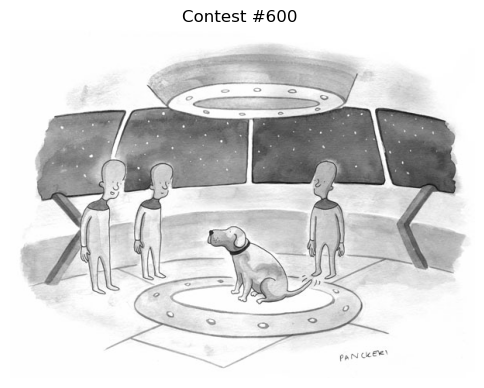


Contest 600 Top Caption:
Rank 1: 'Mission accomplished. We will report that this planet's inhabitants are friendly and playful.' with mean score 2.999


In [11]:
print("Contest with the best mean score on top 1 captions : ")
show_contest_image(600)
print_top_caption(600, folder_path)



Contest with the worst mean score on top 1 captions : 


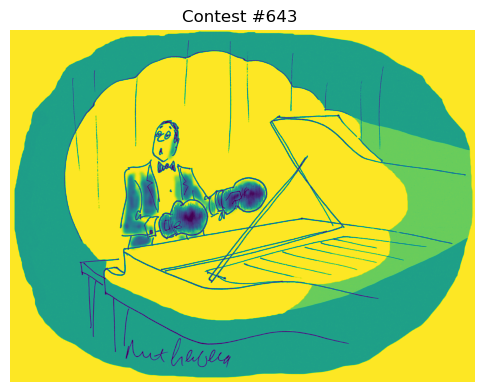


Contest 643 Top Caption:
Rank 1: 'My next selection sounds just like the last one.' with mean score 1.552


In [12]:
print("Contest with the worst mean score on top 1 captions : ")
show_contest_image(643)
print_top_caption(643, folder_path)



2.1 Plotting the Delta of the top 2 Best-rated captions (in terms of mean)

The aim here is to see if there is a strong disparity of popularity between the first and second best captions in all the contests. This will help us understand if the winning captions are usually outliers.
To assess how good a caption was, I used its mean score.

In [13]:
#print top 2 captions
def print_top2_captions_with_delta(contest_num, folder_path):
    filename = f"{contest_num}.csv"
    file_path = os.path.join(folder_path, filename)
    
    df = pd.read_csv(file_path)
    top2 = df.nlargest(2, 'mean')  # top 2 captions by mean score
    
    delta = top2.iloc[0]['mean'] - top2.iloc[1]['mean']
    
    print(f"\nContest {contest_num} Top 2 Captions (Delta = {delta:.3f}):")
    for i, row in top2.iterrows():
        print(f"Rank {i+1}: '{row['caption']}' with mean score {row['mean']:.3f}")

In [15]:
top2_delta = {} #computing the delta between the top 2 captions
for contest_num in range(510, 896):
    filename = f"{contest_num}.csv"
    file_path = os.path.join(folder_path, filename)
    if os.path.exists(file_path):
        try:
            df = pd.read_csv(file_path)
            if len(df) >= 2: #removing empty contest (if they have less than 2 captions, not sure if this is necessary though)
                top_scores = df['mean'].nlargest(2).values #making sure it's the two highest mean
                margin = top_scores[0] - top_scores[1]
                top2_delta[contest_num] = margin
            else:
                top2_delta[contest_num] = None
        except Exception as e:
            print(f"Error reading {filename}: {e}")
    else:
        top2_delta[contest_num] = None

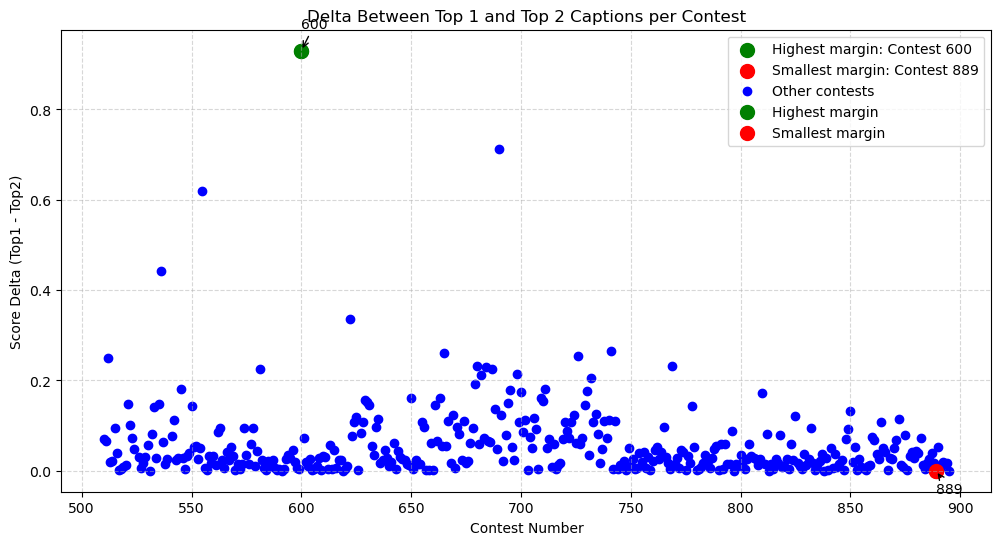

In [16]:
margin_df = pd.DataFrame(list(top2_delta.items()), columns=["Contest", "Top2_Delta"])
margin_df = margin_df.dropna()  # once again making sure our DataFrame only has real data, not sure if this is necessary
max_contest = margin_df.loc[margin_df["Top2_Delta"].idxmax()] #Contest with the highest Delta
min_contest = margin_df.loc[margin_df["Top2_Delta"].idxmin()] #Contest with the lowest Delta
plt.figure(figsize=(12,6))
plt.scatter(max_contest['Contest'], max_contest['Top2_Delta'], color='green', s=100, 
            label=f'Highest margin: Contest {int(max_contest["Contest"])}')
plt.scatter(min_contest['Contest'], min_contest['Top2_Delta'], color='red', s=100, 
            label=f'Smallest margin: Contest {int(min_contest["Contest"])}')
# Plotting all the deltas
plt.scatter(margin_df["Contest"], margin_df["Top2_Delta"], color='blue', label='Other contests')

# Highlighting highest and lowest delta
plt.scatter(max_contest['Contest'], max_contest['Top2_Delta'], color='green', s=100, label='Highest margin')
plt.scatter(min_contest['Contest'], min_contest['Top2_Delta'], color='red', s=100, label='Smallest margin')

#Annotating Highest and Lowest delta
plt.annotate(f"{int(max_contest['Contest'])}", 
             xy=(max_contest['Contest'], max_contest['Top2_Delta']),
             xytext=(max_contest['Contest'], max_contest['Top2_Delta'] + 0.05),
             arrowprops=dict(facecolor='green', arrowstyle='->'),
             fontsize=10)

plt.annotate(f"{int(min_contest['Contest'])}", 
             xy=(min_contest['Contest'], min_contest['Top2_Delta']),
             xytext=(min_contest['Contest'], min_contest['Top2_Delta'] - 0.05),
             arrowprops=dict(facecolor='red', arrowstyle='->'),
             fontsize=10)

plt.title("Delta Between Top 1 and Top 2 Captions per Contest")
plt.xlabel("Contest Number")
plt.ylabel("Score Delta (Top1 - Top2)")
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()  
plt.show()

Contest with the highest delta of scores between the top 2 captions : 


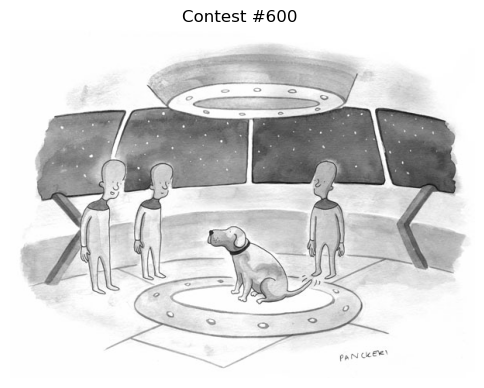


Contest 600 Top 2 Captions (Delta = 0.930):
Rank 1: 'Mission accomplished. We will report that this planet's inhabitants are friendly and playful.' with mean score 2.999
Rank 2: 'When I said abduct the dog, I meant President Trump...' with mean score 2.069


In [17]:
print("Contest with the highest delta of scores between the top 2 captions : ")
show_contest_image(600)
print_top2_captions_with_delta(int(max_contest['Contest']), folder_path)


This proves that for contest #600, the best rated caption won with a lot of margin (delta= 0.930). It is important to also note that there is quite a difference between the total number of votes for each captions. Rank 1 has 924 votes while Rank 2 only has 29.

Contest with the lowest delta of scores between the top 2 captions : 


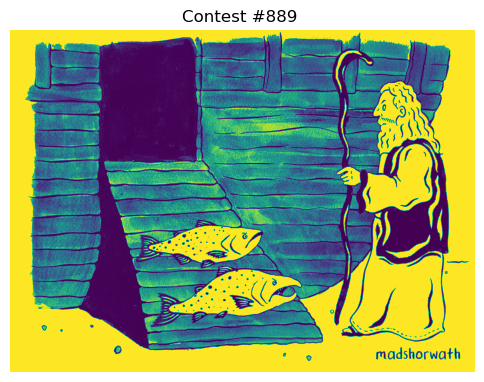


Contest 889 Top 2 Captions (Delta = 0.000):
Rank 1: 'You say ‘flood’ like it’s a bad thing.' with mean score 1.754
Rank 2: 'Why don’t we just meet you there?' with mean score 1.754


In [19]:
print("Contest with the lowest delta of scores between the top 2 captions : ")
show_contest_image(889)
print_top2_captions_with_delta(int(min_contest['Contest']), folder_path)


For contest #889, the best rated caption didn't win by any margin (less than 0,001). It had, however more total votes.